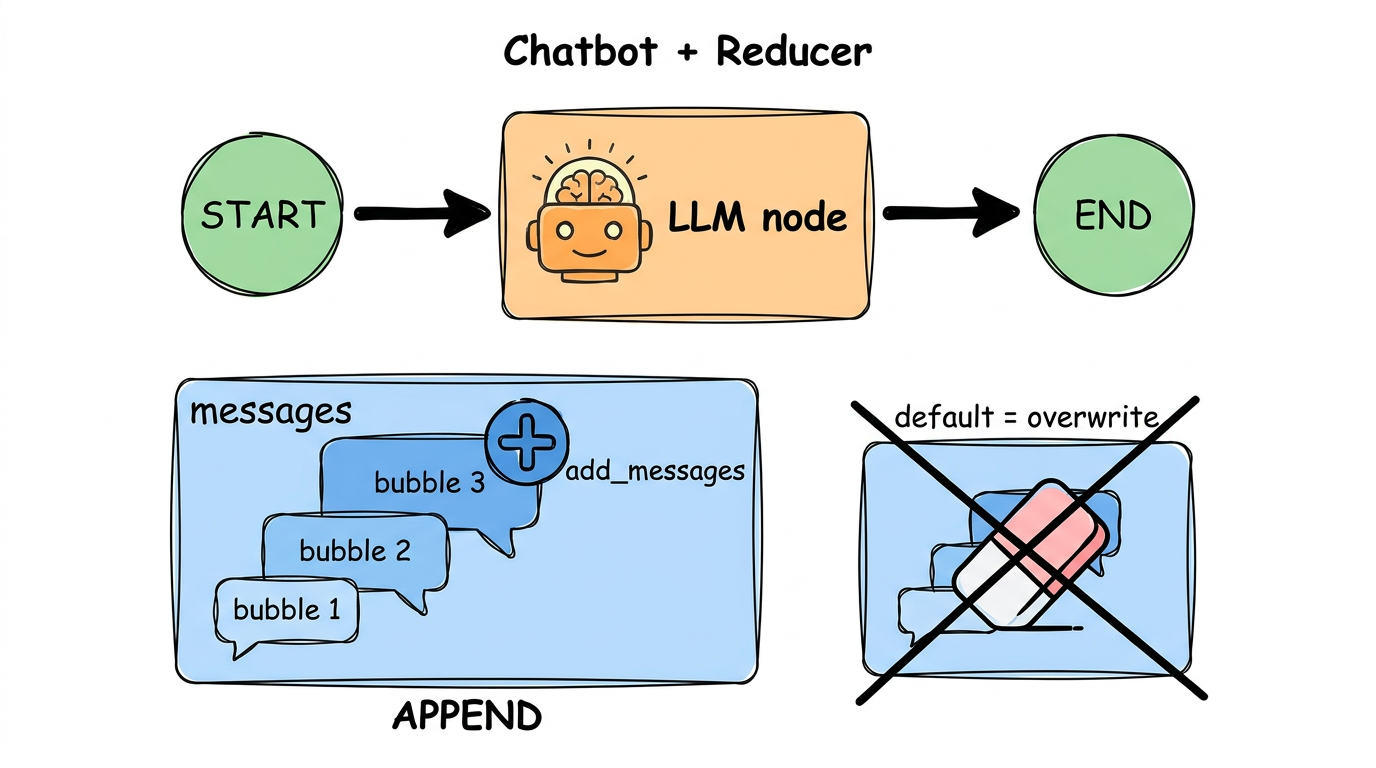

### **Implementing simple Chatbot Using LangGraph**

In [1]:
from typing_extensions import TypedDict

from langgraph.graph import StateGraph, START, END

## Reducers
from typing import Annotated
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    messages:Annotated[list,add_messages]

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()


True

In [4]:
from langchain_openai import AzureChatOpenAI

llm = AzureChatOpenAI(
    azure_deployment="gpt-4.1-mini",
    temperature=0,
    api_version="2024-12-01-preview"
)

response = llm.invoke("Hello")

print(response.content)

Hello! How can I assist you today?


#### We Will start With Creating Nodes

In [5]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

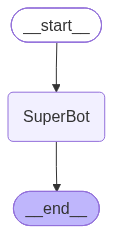

In [6]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile()


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [7]:
graph_builder.invoke({'messages':"Hi,My name is Munavar And I like cricket"})

{'messages': [HumanMessage(content='Hi,My name is Munavar And I like cricket', additional_kwargs={}, response_metadata={}, id='284dc6d0-3ae4-455c-8623-39c897c33b03'),
  AIMessage(content="Hi Munavar! It's great to meet you. Cricket is such an exciting sport! Do you have a favorite team or player?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 26, 'prompt_tokens': 18, 'total_tokens': 44, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}, 'latency_checkpoint': {'engine_tbt_ms': 7, 'engine_ttft_ms': 28, 'engine_ttlt_ms': 208, 'pre_inference_ms': 115, 'service_tbt_ms': 10, 'service_ttft_ms': 704, 'service_ttlt_ms': 959, 'user_visible_ttft_ms': 589}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_36de3d5958', 'id': '

#### Streaming The responses

In [9]:
for event in graph_builder.stream({"messages":"Hello My name is Munavar"}):
    print(event)

{'SuperBot': {'messages': [AIMessage(content='Hello Munavar! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 11, 'prompt_tokens': 13, 'total_tokens': 24, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0}, 'latency_checkpoint': {'engine_tbt_ms': 7, 'engine_ttft_ms': 31, 'engine_ttlt_ms': 113, 'pre_inference_ms': 205, 'service_tbt_ms': 23, 'service_ttft_ms': 756, 'service_ttlt_ms': 1007, 'user_visible_ttft_ms': 552}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_36de3d5958', 'id': 'chatcmpl-ElwxBu3MZvn3wOFDufsq3oki2G3No', 'service_tier': 'default', 'prompt_filter_results': [{'prompt_index': 0, 'content_filter_results': {'hate': {'filtered': False, 'severity': 'safe'}, 'jailbreak': {'det